### 23BAI1301-Sparsh Patidar
### 23BAI1254 - Hemant
### 23BAI1303 - Khwaish Yadav
### Image-Based Wafer Map Pattern Intelligence:Autoencoder-Assisted Deep Learning Framework for Defect Pattern Classification

In [ ]:

import kagglehub
qingyi_wm811k_wafer_map_path = kagglehub.dataset_download('qingyi/wm811k-wafer-map')
truthr_torchsummary_path = kagglehub.dataset_download('truthr/torchsummary')

print('Data source import complete.')


In [ ]:
# Load in our libraries
import pandas as pd
import numpy as np
import sklearn
import xgboost as xgb
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
plt.style.use('seaborn')
sns.set(font_scale=2)


%matplotlib inline
import torch
import torchvision
from PIL import Image

In [ ]:
df = pd.read_pickle("../input/wm811k-wafer-map/LSWMD.pkl")

In [ ]:
df.info() #dataset check.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 811457 entries, 0 to 811456
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   waferMap        811457 non-null  object 
 1   dieSize         811457 non-null  float64
 2   lotName         811457 non-null  object 
 3   waferIndex      811457 non-null  float64
 4   trianTestLabel  811457 non-null  object 
 5   failureType     811457 non-null  object 
dtypes: float64(2), object(4)
memory usage: 37.1+ MB


In [ ]:
df.head()

,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]


In [ ]:
df.tail()

,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
811452,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1,...",600.0,lot47542,23.0,[[Test]],[[Edge-Ring]]
811453,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 1, 1,...",600.0,lot47542,24.0,[[Test]],[[Edge-Loc]]
811454,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1,...",600.0,lot47542,25.0,[[Test]],[[Edge-Ring]]
811455,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,...",600.0,lot47543,1.0,[],[]
811456,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1,...",600.0,lot47543,2.0,[],[]


dataset has 47543 lot. Theoretically, there must be 25*47543 waferMap. but last Index is 811456.
Let's check this problem.

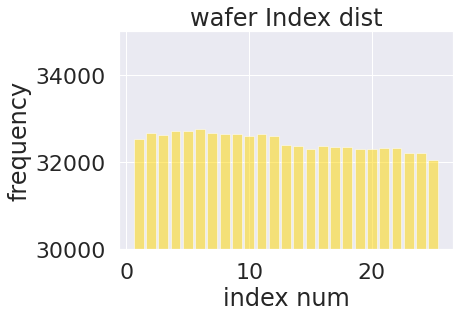

In [ ]:
lot_index = np.unique(df.waferIndex, return_counts=True)
plt.bar(lot_index[0], lot_index[1], color='gold', align = 'center', alpha = 0.5)
plt.title("wafer Index dist")
plt.xlabel("index num")
plt.ylabel("frequency")
plt.ylim(30000, 35000)
plt.show()

each index frequency is not equal, but we're not use this column.
so drop waferIndex column.

In [ ]:
df = df.drop(['waferIndex'], axis = 1)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 811457 entries, 0 to 811456
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   waferMap        811457 non-null  object 
 1   dieSize         811457 non-null  float64
 2   lotName         811457 non-null  object 
 3   trianTestLabel  811457 non-null  object 
 4   failureType     811457 non-null  object 
dtypes: float64(1), object(4)
memory usage: 31.0+ MB


In [ ]:
#add wafermapDim column because waferMap dim is different each other.
def find_dim(x):
    dim0=np.size(x,axis=0)
    dim1=np.size(x,axis=1)
    return dim0,dim1
df['waferMapDim']=df.waferMap.apply(find_dim)
df.sample(5)

,waferMap,dieSize,lotName,trianTestLabel,failureType,waferMapDim
425057,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 2,...",592.0,lot25497,[],[],"(29, 27)"
420769,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",5532.0,lot25264,[],[],"(60, 119)"
229131,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",5633.0,lot14363,[],[],"(88, 81)"
10029,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,...",537.0,lot1894,[],[],"(25, 28)"
787346,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,...",953.0,lot46562,[[Test]],[[none]],"(33, 37)"


In [ ]:
#To check failureType# and class dist.
df['failureNum'] = df.failureType
mapping_type={'Center':0,'Donut':1,'Edge-Loc':2,'Edge-Ring':3,'Loc':4,'Random':5,'Scratch':6,'Near-full':7,'none':8}
df=df.replace({'failureNum':mapping_type})

/opt/conda/lib/python3.7/site-packages/pandas/core/array_algos/replace.py:60: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  op = lambda x: operator.eq(x, b)


In [ ]:

df_withlabel = df[(df['failureType']!=0)]
df_withlabel =df_withlabel.reset_index() #labeled index.
df_withpattern = df_withlabel[(df_withlabel['failureType'] != 'none')]
df_withpattern = df_withpattern.reset_index() #patterned index.
df_nonpattern = df_withlabel[(df_withlabel['failureType'] == 'none')] #nonpatterned index
df_withlabel.shape[0], df_withpattern.shape[0], df_nonpattern.shape[0]

/opt/conda/lib/python3.7/site-packages/pandas/core/ops/array_ops.py:55: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  result = libops.scalar_compare(x.ravel(), y, op)


(172950, 25519, 147431)

/opt/conda/lib/python3.7/site-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


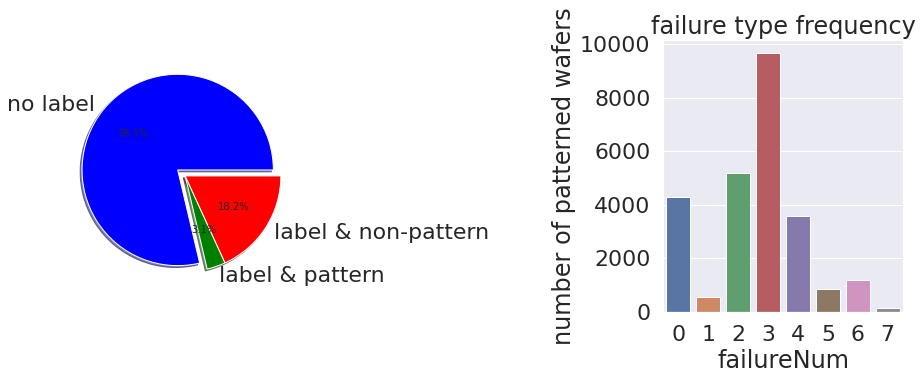

In [ ]:
fig,ax = plt.subplots(1,2, figsize = (15,5))
colors = ['blue', 'green', 'red']
num_wafers=[len(df['waferMap'])-df_withlabel.shape[0], df_withpattern.shape[0], df_nonpattern.shape[0]]
labels = ['no label', 'label & pattern', 'label & non-pattern']
ax[0].pie(num_wafers, explode=(0.1,0,0), labels = labels, colors = colors, autopct = '%1.1f%%', shadow=True)
sns.countplot('failureNum', data=df_withpattern, ax=ax[1])
ax[1].set_title("failure type frequency")
ax[1].set_ylabel("number of patterned wafers")
plt.subplots_adjust(wspace = 1.5)
plt.show()

In [ ]:
df_withlabel['waferMapDim'].value_counts()

(25, 27)      18781
(26, 26)      14366
(30, 34)      12400
(29, 26)      11751
(27, 25)      10682
              ...  
(41, 39)          1
(122, 104)        1
(54, 54)          1
(109, 111)        1
(43, 133)         1
Name: waferMapDim, Length: 346, dtype: int64

In [ ]:
#extract (25,27) & (26,26) waferMapDim data
def subwafer(sw,label):
  Dim0 = np.size(sw, axis=1)
  Dim1 = np.size(sw, axis=2)
  sub_df = df_withlabel.loc[df_withlabel['waferMapDim'] == (Dim0, Dim1)]
  sub_wafer = sub_df['waferMap'].values
  sw = sw.to(torch.device('cuda'))
  for i in range(len(sub_df)):
    waferMap = torch.from_numpy(sub_df.iloc[i,:]['waferMap'].reshape(1, Dim0, Dim1))
    waferMap = waferMap.to(torch.device('cuda'))
    sw = torch.cat([sw, waferMap])
    label.append(sub_df.iloc[i,:]['failureType'][0][0])
  x = sw[1:]
  y = np.array(label).reshape((-1,1))
  del waferMap, sw
  return x, y

In [ ]:
sw0 = torch.ones((1, 25, 27))
sw1 = torch.ones((1, 26, 26))
label0 = list()
label1 = list()

In [ ]:
x0, y0 = subwafer(sw0, label0)
x1, y1 = subwafer(sw1, label1)

In [ ]:
x0.shape, x1.shape

(torch.Size([18781, 25, 27]), torch.Size([14366, 26, 26]))

In [ ]:
#add RGB space for one-hot encoding
# 0: non wafer -> R, 1: normal die -> G, 2: defect die -> B|

def rgb_sw(x):
  Dim0 = np.size(x, axis=1)
  Dim1 = np.size(x, axis=2)
  new_x = np.zeros((len(x), Dim0, Dim1, 3))
  x = torch.unsqueeze(x,-1)
  x = x.to(torch.device('cpu'))
  x = x.numpy()
  for w in range(len(x)):
      for i in range(Dim0):
          for j in range(Dim1):
              new_x[w, i, j, int(x[w, i, j])] = 1
  return new_x

In [ ]:
rgb_x0 = rgb_sw(x0) #about 8s each line.
rgb_x1 = rgb_sw(x1)

In [ ]:
del x0, x1 #delete useless data

In [ ]:
#To use two dim, we have to resize these data.
def resize(x):
  rwm = torch.ones((1,56,56,3))
  for i in range(len(x)):
    rwm = rwm.to(torch.device('cuda'))
    a = Image.fromarray(x[i].astype('uint8')).resize((56,56))
    a = np.array(a).reshape((1,56,56,3))
    a = torch.from_numpy(a)
    a = a.to(torch.device('cuda'))
    rwm = torch.cat([rwm, a])
  x = rwm[1:]
  del rwm
  return x

In [ ]:
resized_x0 = resize(rgb_x0)
resized_x1 = resize(rgb_x1)

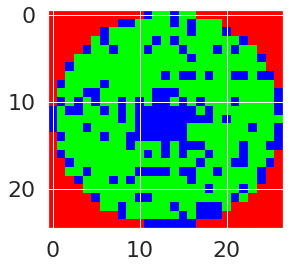

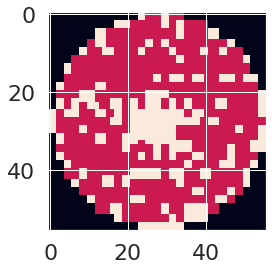

In [ ]:
plt.imshow(rgb_x0[1000])
plt.show()
plt.imshow(torch.argmax(resized_x0[1000],axis=2).cpu().numpy())
plt.show()
# reszied_wafer is added some noise. but I think for classification pattern, some noise is not important.

In [ ]:
del rgb_x0, rgb_x1 #delete useless data

In [ ]:
resized_wm = torch.cat([resized_x0, resized_x1])
label_wm = np.concatenate((y0,y1)) #concatenate To use all data.

In [ ]:
del y0,y1,resized_x0, resized_x1

In [ ]:
#Convolutional Autoencoder
# parameter
args = {
	'BATCH_SIZE': 16,
        'LEARNING_RATE': 0.001,
        'NUM_EPOCH': 10
        }

In [ ]:
resized_wm = resized_wm.permute(0,3,1,2)

In [ ]:
USE_CUDA = torch.cuda.is_available()
DEVICE = torch.device("cuda" if USE_CUDA else "cpu")
train_loader  = torch.utils.data.DataLoader(resized_wm, args['BATCH_SIZE'], shuffle=True)

In [ ]:
resized_wm.shape, label_wm.shape

(torch.Size([33147, 3, 56, 56]), (33147, 1))

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.nn.init
from torch.utils.data import Dataset, DataLoader,TensorDataset,random_split,SubsetRandomSampler, ConcatDataset

In [ ]:
class ConvAutoEncoder(nn.Module):
    def __init__(self):
        super(ConvAutoEncoder, self).__init__()

        # Encoder
        self.cnn_layer1 = nn.Sequential(
                        nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1),
                        nn.ReLU(),
                         nn.MaxPool2d(2,2))

        self.cnn_layer2 = nn.Sequential(
                                nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
                                nn.ReLU(),
                                 nn.MaxPool2d(2,2))

        # Decoder
        self.tran_cnn_layer1 = nn.Sequential(
                        nn.ConvTranspose2d(32, 16, kernel_size = 2, stride = 2, padding=0),
                        nn.ReLU())

        self.tran_cnn_layer2 = nn.Sequential(
                        nn.ConvTranspose2d(16, 3, kernel_size = 2, stride = 2, padding=0),
                        nn.Sigmoid())

    def encoder(self, x):
        encode = self.cnn_layer1(x)
        encode = self.cnn_layer2(encode)
        return encode

    def decoder(self, x):
        decode = self.tran_cnn_layer1(x)
        decode = self.tran_cnn_layer2(decode)
        return decode

    def forward(self, x):
        output = self.encoder(x)
        output = self.decoder(output)
        return output

In [ ]:
model = ConvAutoEncoder().to(DEVICE)
print(model)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=args['LEARNING_RATE'])

ConvAutoEncoder(
  (cnn_layer1): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (cnn_layer2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (tran_cnn_layer1): Sequential(
    (0): ConvTranspose2d(32, 16, kernel_size=(2, 2), stride=(2, 2))
    (1): ReLU()
  )
  (tran_cnn_layer2): Sequential(
    (0): ConvTranspose2d(16, 3, kernel_size=(2, 2), stride=(2, 2))
    (1): Sigmoid()
  )
)


In [ ]:
!pip install ../input/torchsummary/torchsummary-1.5.1-py3-none-any.whl

Processing /kaggle/input/torchsummary/torchsummary-1.5.1-py3-none-any.whl


In [ ]:
from torchsummary import summary
summary(model,(3,54,54), batch_size=16)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [16, 16, 54, 54]             448
              ReLU-2           [16, 16, 54, 54]               0
         MaxPool2d-3           [16, 16, 27, 27]               0
            Conv2d-4           [16, 32, 27, 27]           4,640
              ReLU-5           [16, 32, 27, 27]               0
         MaxPool2d-6           [16, 32, 13, 13]               0
   ConvTranspose2d-7           [16, 16, 26, 26]           2,064
              ReLU-8           [16, 16, 26, 26]               0
   ConvTranspose2d-9            [16, 3, 52, 52]             195
          Sigmoid-10            [16, 3, 52, 52]               0
Total params: 7,347
Trainable params: 7,347
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.53
Forward/backward pass size (MB): 23.79
Params size (MB): 0.03
Estimated Tota

In [ ]:
steps = 0
print(resized_wm.shape)
total_steps = len(train_loader)
losses =[]
iterations = []
for epoch in range(args['NUM_EPOCH']):
    running_loss = 0.0
    for i,wafer in enumerate(train_loader):
        steps += 1
        wafer = wafer.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(wafer)
        loss = criterion(outputs, wafer) #autoencoder loss : compare input & output
        loss.backward()
        running_loss += loss.item()*wafer.shape[0]
        optimizer.step()
        if steps % total_steps == 0:
            model.eval()
            print('Epoch: {}/{}'.format(epoch+1, args['NUM_EPOCH']),
                 "=> loss : %.3f"%(running_loss/total_steps))
            steps = 0
            iterations.append(i)
            losses.append(running_loss / total_steps)
            model.train()

torch.Size([33147, 3, 56, 56])
Epoch: 1/10 => loss : 0.524
Epoch: 2/10 => loss : 0.146
Epoch: 3/10 => loss : 0.102
Epoch: 4/10 => loss : 0.085
Epoch: 5/10 => loss : 0.075
Epoch: 6/10 => loss : 0.068
Epoch: 7/10 => loss : 0.063
Epoch: 8/10 => loss : 0.059
Epoch: 9/10 => loss : 0.056
Epoch: 10/10 => loss : 0.054


In [ ]:
del wafer, optimizer, loss

In [ ]:
faulty_case = np.unique(label_wm)
print(faulty_case)

['Center' 'Donut' 'Edge-Loc' 'Edge-Ring' 'Loc' 'Near-full' 'Random'
 'Scratch' 'none']


In [ ]:
import torch.nn.init
# augment function define
def gen_data(wafer, label):
  gen_x = torch.zeros((1, 3, 56, 56))
  with torch.no_grad():
    encoded_x = model.encoder(wafer).to(torch.device('cpu'))
    # dummy array for collecting noised wafer
    # Make wafer until total # of wafer to 2000
    for i in range((2000//len(wafer)) + 1):
      noised_encoded_x = (encoded_x + torch.from_numpy(np.random.normal(loc=0, scale=0.1, size = (len(encoded_x), 32, 14, 14))).to(torch.device('cpu'))).to(DEVICE)
      noised_decoded_x = model.decoder(noised_encoded_x.float()).to(torch.device('cpu'))
      gen_x = torch.cat([gen_x, noised_decoded_x], axis=0)
    # also make label vector with same length
    gen_y = np.full((len(gen_x), 1), label)
    # return date without 1st dummy data.
  del encoded_x, noised_encoded_x, noised_decoded_x
  return gen_x[1:], gen_y[1:]

In [ ]:
# Augmentation for all faulty case.
for f in faulty_case :
    # skip none case
    if f == 'none' :
        continue
    gen_x, gen_y = gen_data(resized_wm[np.where(label_wm==f)[0]].to(DEVICE), f)
    resized_wm = torch.cat([resized_wm.to(torch.device('cpu')), gen_x], axis=0)
    label_wm = np.concatenate((label_wm, gen_y))

In [ ]:
print('After Generate resized_wm shape : {}, label_wm shape : {}'.format(resized_wm.shape, label_wm.shape))
del gen_x, gen_y

After Generate resized_wm shape : torch.Size([50611, 3, 56, 56]), label_wm shape : (50611, 1)


In [ ]:
none_idx = np.where(label_wm=='none')[0][np.random.choice(len(np.where(label_wm=='none')[0]), size=27150, replace=False)]
EdgeLoc_idx = np.where(label_wm=='Edge-Loc')[0][np.random.choice(len(np.where(label_wm=='Edge-Loc')[0]), size=1100, replace=False)]
Center_idx = np.where(label_wm=='Center')[0][np.random.choice(len(np.where(label_wm=='Center')[0]), size=2500, replace=False)]
Loc_idx = np.where(label_wm=='Loc')[0][np.random.choice(len(np.where(label_wm=='Loc')[0]), size=600, replace=False)]

In [ ]:
delete_idx = np.concatenate((none_idx, EdgeLoc_idx, Center_idx, Loc_idx))
delete_idx.shape

(31350,)

In [ ]:
resized_wm.shape

torch.Size([50611, 3, 56, 56])

In [ ]:
remove_wm = np.delete(resized_wm.detach().cpu().numpy(), delete_idx, axis=0)
resized_wm = torch.from_numpy(remove_wm)

In [ ]:
del_idx = np.concatenate((none_idx, EdgeLoc_idx, Center_idx, Loc_idx))
label_wm = np.delete(label_wm, del_idx, axis=0)

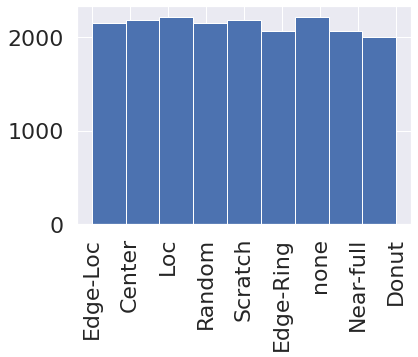

In [ ]:
n, bins, patches = plt.hist(label_wm, bins=9)
plt.xticks(rotation=90)
plt.show()

In [ ]:
# one-hot-encoding
for i, l in enumerate(faulty_case):
    label_wm[label_wm==l] = i
    print('i : {}, l : {}'.format(i, l))
def _to_one_hot(y, num_classes):
    scatter_dim = len(y.size())
    y_tensor = y.view(*y.size(), -1)
    zeros = torch.zeros(*y.size(), num_classes, dtype=y.dtype)
    return zeros.scatter(scatter_dim, y_tensor, 1)

label_wm = _to_one_hot(torch.as_tensor(np.int64(label_wm)), num_classes=9)

i : 0, l : Center
i : 1, l : Donut
i : 2, l : Edge-Loc
i : 3, l : Edge-Ring
i : 4, l : Loc
i : 5, l : Near-full
i : 6, l : Random
i : 7, l : Scratch
i : 8, l : none


In [ ]:
import torch.utils.data as data
class BasicDataset(data.Dataset):
    def __init__(self, x_tensor, y_tensor):
        super(BasicDataset, self).__init__()

        self.x = x_tensor
        self.y = y_tensor

    def __getitem__(self, index):
        return self.x[index], self.y[index]

    def __len__(self):
        return len(self.x)

In [ ]:
from sklearn import model_selection

In [ ]:
train_X, test_X, train_Y, test_Y = model_selection.train_test_split(resized_wm, label_wm , test_size=0.2)
dataset_train = BasicDataset(train_X,train_Y)
dataset_test = BasicDataset(test_X, test_Y)
dataset = ConcatDataset([dataset_train, dataset_test])

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.keep_prob1 = 0.2
        self.keep_prob2 = 0.5

        self.layer1 =nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2))


        self.layer2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2))


        self.layer3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=1))

        self.fc1 = nn.Linear(8 * 8 * 128, 1250, bias=True)
        nn.init.xavier_uniform_(self.fc1.weight)
        self.layer4 = nn.Sequential(
            self.fc1,
            nn.ReLU())

        self.fc2 = nn.Linear(1250, 9, bias=True)
        nn.init.xavier_uniform_(self.fc2.weight)


    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = self.layer3(out)
        out = out.view(out.size(0), -1)
        out = self.layer4(out)
        out = self.fc2(out)
        return out

In [ ]:
CNN = CNN().to(DEVICE)
print(CNN)
summary(CNN,(3,56,56), batch_size=16)

CNN(
  (layer1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=1, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=8192, out_features=1250, bias=True)
  (layer4): Sequential(
    (0): Linear(in_features=8192, out_features=1250, bias=True)
    (1): ReLU()
  )
  (fc2): Linear(in_features=1250, out_features=9, bias=True)
)
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1  

In [ ]:
args = {
	'BATCH_SIZE': 256,
        'LEARNING_RATE': 0.005,
        'NUM_EPOCH': 10
        }

In [ ]:

criterion = torch.nn.CrossEntropyLoss().to(DEVICE)
optimizer = torch.optim.Adam(CNN.parameters(), lr=args['LEARNING_RATE'])
torch.manual_seed(42)
splits = KFold(n_splits=5, shuffle = True, random_state = 42)
foldperf={}

In [ ]:
def train_epoch(model, dataloader,loss_fn,optimizer):
    train_loss,train_correct=0.0,0
    model.train()
    for images, labels in dataloader:
        images,labels = images.to(DEVICE),labels.to(DEVICE).reshape(args['BATCH_SIZE'], 9)
        optimizer.zero_grad()
        output = model(images)
        labels = torch.argmax(labels, dim=1)
        loss = loss_fn(output,labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * images.size(0)
        predictions = torch.argmax(output, 1)
        train_correct += (predictions == labels).sum().item()
    print(train_correct)
    return train_loss,train_correct

def valid_epoch(model,dataloader,loss_fn):
    valid_loss, val_correct = 0.0, 0
    model.eval()
    for images, labels in dataloader:
        images,labels = images.to(DEVICE),labels.to(DEVICE).reshape(args['BATCH_SIZE'],9)
        output = model(images)
        labels = torch.argmax(labels, dim=1)
        loss=loss_fn(output,labels)
        valid_loss+=loss.item() * images.size(0)
        predictions = torch.argmax(output, 1)
        val_correct+=(predictions == labels).sum().item()
    return valid_loss,val_correct

In [ ]:
for fold, (train_idx,val_idx) in enumerate(splits.split(np.arange(len(dataset)))):
    print('Fold {}'.format(fold + 1))

    train_sampler = SubsetRandomSampler(train_idx)
    test_sampler = SubsetRandomSampler(val_idx)
    train_loader = DataLoader(dataset, batch_size=args['BATCH_SIZE'], sampler=train_sampler, drop_last=True)
    test_loader = DataLoader(dataset, batch_size=args['BATCH_SIZE'], sampler=test_sampler, drop_last=True)
    history = {'train_loss': [], 'test_loss': [],'train_acc':[],'test_acc':[]}

    for epoch in range(args['NUM_EPOCH']):
        train_loss, train_correct=train_epoch(CNN,train_loader,criterion,optimizer)
        test_loss, test_correct=valid_epoch(CNN,test_loader,criterion)
        train_loss = train_loss / len(train_loader.sampler)
        train_acc = train_correct / len(train_loader.sampler) * 100
        test_loss = test_loss / len(test_loader.sampler)
        test_acc = test_correct / len(test_loader.sampler) * 100

        print("Epoch:{}/{} AVG Training Loss:{:.3f} AVG Test Loss:{:.3f} AVG Training Acc {:.2f} % AVG Test Acc {:.2f} %".format(epoch + 1,
                                                                                                             args['NUM_EPOCH'],
                                                                                                             train_loss,
                                                                                                             test_loss,
                                                                                                             train_acc,
                                                                                                             test_acc))
        history['train_loss'].append(train_loss)
        history['test_loss'].append(test_loss)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)

    foldperf['fold{}'.format(fold+1)] = history

torch.save(model,'k_cross_CNN.pt')

Fold 1
8866
Epoch:1/10 AVG Training Loss:1.436 AVG Test Loss:0.451 AVG Training Acc 57.54 % AVG Test Acc 82.43 %
13068
Epoch:2/10 AVG Training Loss:0.389 AVG Test Loss:0.298 AVG Training Acc 84.81 % AVG Test Acc 90.19 %
14216
Epoch:3/10 AVG Training Loss:0.210 AVG Test Loss:0.147 AVG Training Acc 92.26 % AVG Test Acc 94.73 %
14814
Epoch:4/10 AVG Training Loss:0.106 AVG Test Loss:0.113 AVG Training Acc 96.14 % AVG Test Acc 96.31 %
14638
Epoch:5/10 AVG Training Loss:0.148 AVG Test Loss:0.105 AVG Training Acc 95.00 % AVG Test Acc 96.47 %
15129
Epoch:6/10 AVG Training Loss:0.050 AVG Test Loss:0.068 AVG Training Acc 98.19 % AVG Test Acc 97.35 %
15235
Epoch:7/10 AVG Training Loss:0.030 AVG Test Loss:0.037 AVG Training Acc 98.88 % AVG Test Acc 98.55 %
15258
Epoch:8/10 AVG Training Loss:0.022 AVG Test Loss:0.028 AVG Training Acc 99.03 % AVG Test Acc 98.78 %
15319
Epoch:9/10 AVG Training Loss:0.012 AVG Test Loss:0.041 AVG Training Acc 99.42 % AVG Test Acc 98.16 %
15300
Epoch:10/10 AVG Training 

In [ ]:
testl_f,tl_f,testa_f,ta_f=[],[],[],[]
k=5
for f in range(1,k+1):

     tl_f.append(np.mean(foldperf['fold{}'.format(f)]['train_loss']))
     testl_f.append(np.mean(foldperf['fold{}'.format(f)]['test_loss']))

     ta_f.append(np.mean(foldperf['fold{}'.format(f)]['train_acc']))
     testa_f.append(np.mean(foldperf['fold{}'.format(f)]['test_acc']))

print('Performance of {} fold cross validation'.format(k))
print("Average Training Loss: {:.3f} \t Average Test Loss: {:.3f} \t Average Training Acc: {:.2f} \t Average Test Acc: {:.2f}".format(np.mean(tl_f),np.mean(testl_f),np.mean(ta_f),np.mean(testa_f)))

Performance of 5 fold cross validation
Average Training Loss: 0.067 	 Average Test Loss: 0.068 	 Average Training Acc: 97.67 	 Average Test Acc: 97.88


In [ ]:
tl_f

[0.24203413923097888,
 0.07730534784720669,
 0.0034245708922017427,
 0.002947706128168701,
 0.008649171024733303]

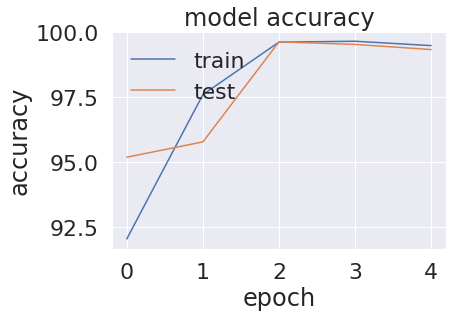

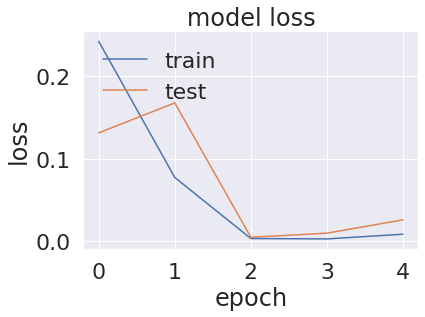

In [ ]:
# accuracy plot
plt.plot(ta_f)
plt.plot(testa_f)
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

# loss plot
plt.plot(tl_f)
plt.plot(testl_f)
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

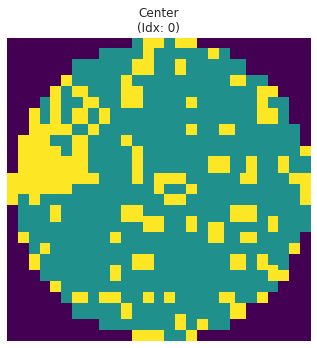

In [ ]:
def plot_defect_samples(x, y, mapping):
    unique_labels = np.unique(y)

    fig, axes = plt.subplots(1, len(unique_labels), figsize=(20, 5), squeeze=False)

    for i, label in enumerate(unique_labels):

        idx = np.where(y == label)[0][0]


        img = x[idx].permute(1, 2, 0).cpu().numpy()

        axes[0, i].imshow(np.argmax(img, axis=2), cmap='viridis')


        title_name = mapping.get(label, f"Class {label}")
        axes[0, i].set_title(f"{title_name}\n(Idx: {label})")
        axes[0, i].axis('off')

    plt.tight_layout()
    plt.show()


y_labels = np.argmax(label_wm.numpy(), axis=1)
plot_defect_samples(resized_wm, y_labels, inv_mapping)

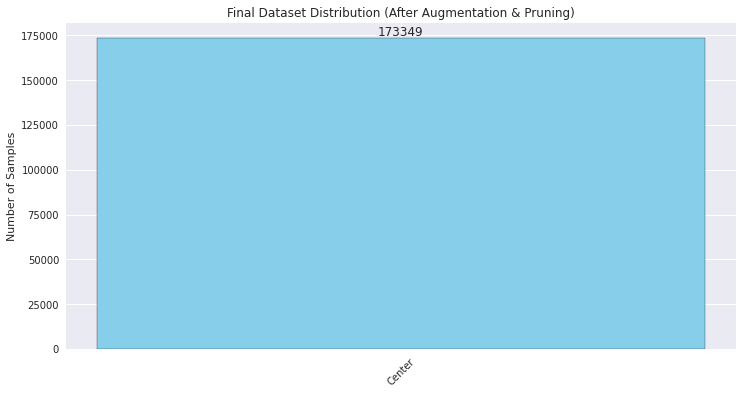

In [ ]:
def plot_final_distribution(y, mapping):
    unique, counts = np.unique(y, return_counts=True)
    labels = [mapping.get(u, str(u)) for u in unique]

    plt.figure(figsize=(12, 6))
    bars = plt.bar(labels, counts, color='skyblue', edgecolor='black')
    plt.xticks(rotation=45)
    plt.ylabel('Number of Samples')
    plt.title('Final Dataset Distribution (After Augmentation & Pruning)')


    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 100, yval, ha='center', va='bottom')

    plt.show()

plot_final_distribution(y_labels, inv_mapping)

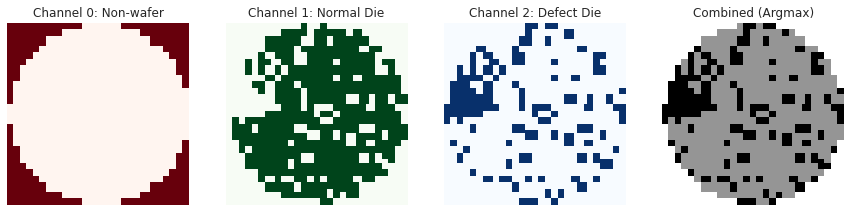

In [ ]:
def visualize_channels(wafer_tensor):
    # Select one wafer
    img = wafer_tensor.permute(1, 2, 0).cpu().numpy()

    fig, axes = plt.subplots(1, 4, figsize=(15, 5))
    axes[0].imshow(img[:,:,0], cmap='Reds')
    axes[0].set_title("Channel 0: Non-wafer")

    axes[1].imshow(img[:,:,1], cmap='Greens')
    axes[1].set_title("Channel 1: Normal Die")

    axes[2].imshow(img[:,:,2], cmap='Blues')
    axes[2].set_title("Channel 2: Defect Die")

    axes[3].imshow(np.argmax(img, axis=2))
    axes[3].set_title("Combined (Argmax)")

    for ax in axes: ax.axis('off')
    plt.show()

visualize_channels(resized_wm[0])

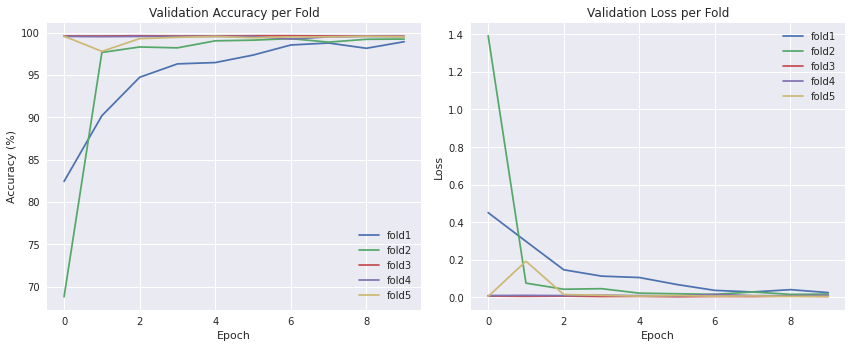

In [ ]:
def plot_kfold_history(foldperf):
    plt.figure(figsize=(12, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    for f in foldperf:
        plt.plot(foldperf[f]['test_acc'], label=f)
    plt.title('Validation Accuracy per Fold')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.legend()

    # Plot Loss
    plt.subplot(1, 2, 2)
    for f in foldperf:
        plt.plot(foldperf[f]['test_loss'], label=f)
    plt.title('Validation Loss per Fold')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_kfold_history(foldperf)

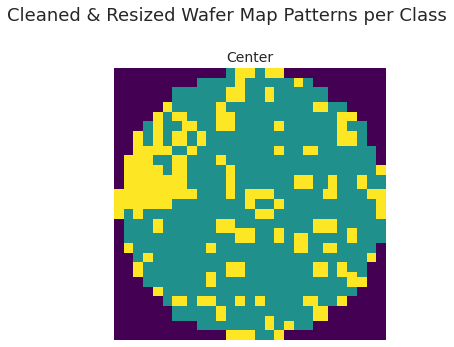

In [ ]:
def plot_defect_samples(x, y, mapping):
    unique_labels = np.unique(y)
    # squeeze=False makes axes[row, col] always work
    fig, axes = plt.subplots(1, len(unique_labels), figsize=(25, 5), squeeze=False)

    for i, label in enumerate(unique_labels):
        # Get the first index of this specific failure type
        idx = np.where(y == label)[0][0]

        # Convert (C, H, W) -> (H, W, C) for plotting
        img = x[idx].permute(1, 2, 0).cpu().numpy()

        # Use argmax to collapse the RGB channels back into a single map
        axes[0, i].imshow(np.argmax(img, axis=2), cmap='viridis')
        axes[0, i].set_title(f"{mapping.get(label, label)}", fontsize=14)
        axes[0, i].axis('off')

    plt.suptitle("Cleaned & Resized Wafer Map Patterns per Class", fontsize=18, y=1.05)
    plt.show()

# Get labels back from one-hot for indexing
y_integers = np.argmax(label_wm.numpy(), axis=1)
inv_mapping = {v: k for k, v in mapping_type.items()}
plot_defect_samples(resized_wm, y_integers, inv_mapping)

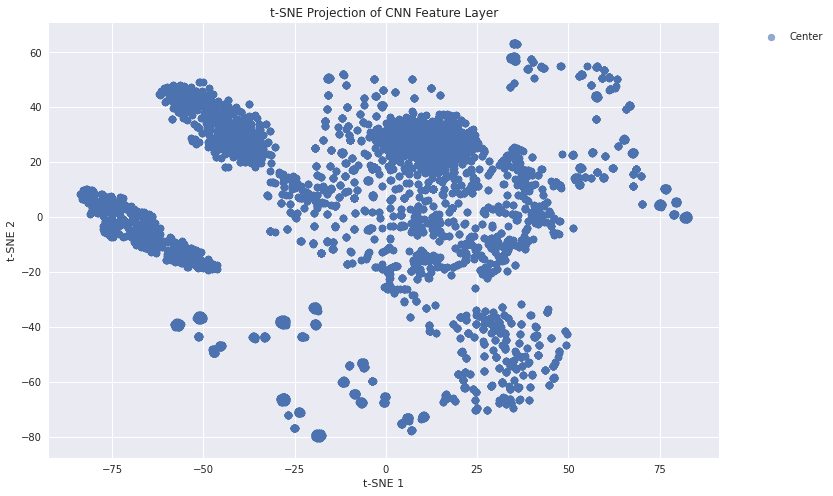

In [ ]:
from sklearn.manifold import TSNE

def plot_tsne_features(model, loader, device, mapping):
    model.eval()
    targets = []
    outputs = []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            # Pass through layers manually to get the layer before the final classifier
            x = model.layer1(inputs)
            x = model.layer2(x)
            x = model.layer3(x)
            x = x.view(x.size(0), -1)
            feat = model.layer4(x) # The 1250-dimensional feature vector

            outputs.append(feat.cpu().numpy())
            targets.append(torch.argmax(labels, dim=1).cpu().numpy())

    outputs = np.concatenate(outputs)
    targets = np.concatenate(targets)

    # Reduce to 2D
    tsne = TSNE(n_components=2, perplexity=30, random_state=42)
    tsne_results = tsne.fit_transform(outputs)

    plt.figure(figsize=(12, 8))
    for label_idx in np.unique(targets):
        idx = np.where(targets == label_idx)
        plt.scatter(tsne_results[idx, 0], tsne_results[idx, 1],
                    label=mapping.get(label_idx, label_idx), alpha=0.6)

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.title("t-SNE Projection of CNN Feature Layer")
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.show()

# Run using the test loader
plot_tsne_features(CNN, test_loader, DEVICE, inv_mapping)

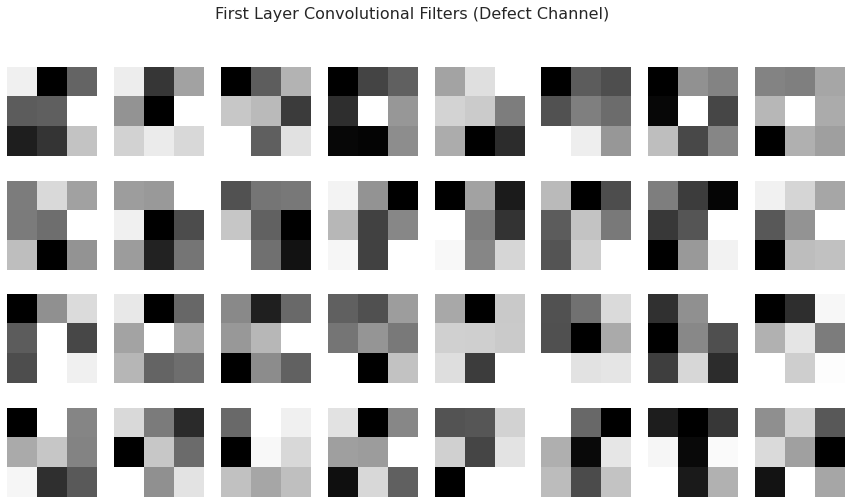

In [ ]:
def plot_filters(model):
    filters = model.layer1[0].weight.data.cpu().numpy()
    fig, axes = plt.subplots(4, 8, figsize=(15, 8))

    for i, ax in enumerate(axes.flat):
        if i < filters.shape[0]:
            # Show the filter for the "Defect" channel (Channel 2)
            ax.imshow(filters[i, 2, :, :], cmap='gray')
            ax.set_xticks([])
            ax.set_yticks([])
    plt.suptitle("First Layer Convolutional Filters (Defect Channel)", fontsize=16)
    plt.show()

plot_filters(CNN)

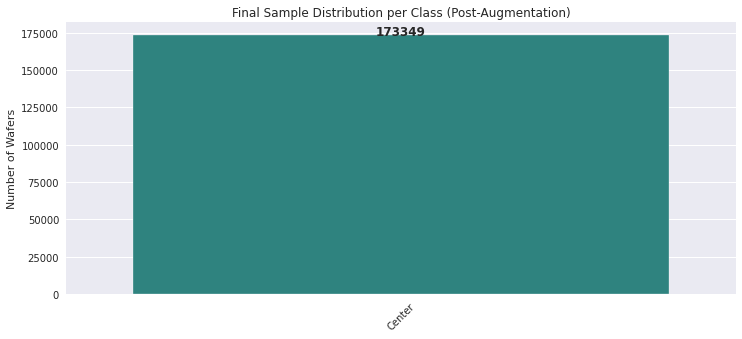

In [ ]:
def plot_final_counts(labels, mapping):
    unique, counts = np.unique(labels, return_counts=True)
    label_names = [mapping.get(u, u) for u in unique]

    plt.figure(figsize=(12, 5))
    sns.barplot(x=label_names, y=counts, palette="viridis")
    plt.title("Final Sample Distribution per Class (Post-Augmentation)")
    plt.ylabel("Number of Wafers")
    plt.xticks(rotation=45)

    # Add count labels on top
    for i, v in enumerate(counts):
        plt.text(i, v + 5, str(v), ha='center', fontweight='bold')
    plt.show()

plot_final_counts(y_integers, inv_mapping)

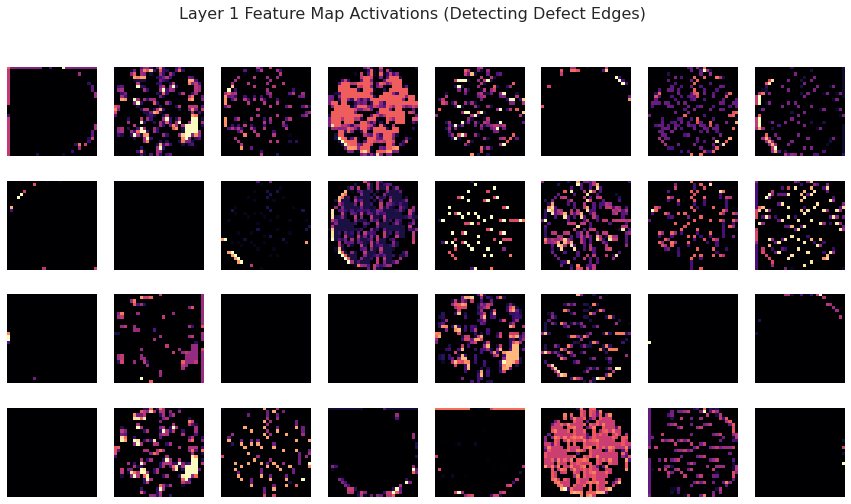

In [ ]:
def plot_feature_maps(model, wafer_tensor, device):
    model.eval()
    with torch.no_grad():
        # Get the first layer output
        input_batch = wafer_tensor.unsqueeze(0).to(device)
        feature_maps = model.layer1(input_batch)

    feature_maps = feature_maps.squeeze(0).cpu().numpy()

    fig, axes = plt.subplots(4, 8, figsize=(15, 8))
    for i, ax in enumerate(axes.flat):
        if i < feature_maps.shape[0]:
            ax.imshow(feature_maps[i], cmap='magma')
        ax.axis('off')
    plt.suptitle("Layer 1 Feature Map Activations (Detecting Defect Edges)", fontsize=16)
    plt.show()

# Visualize for a random wafer
plot_feature_maps(CNN, resized_wm[10], DEVICE)

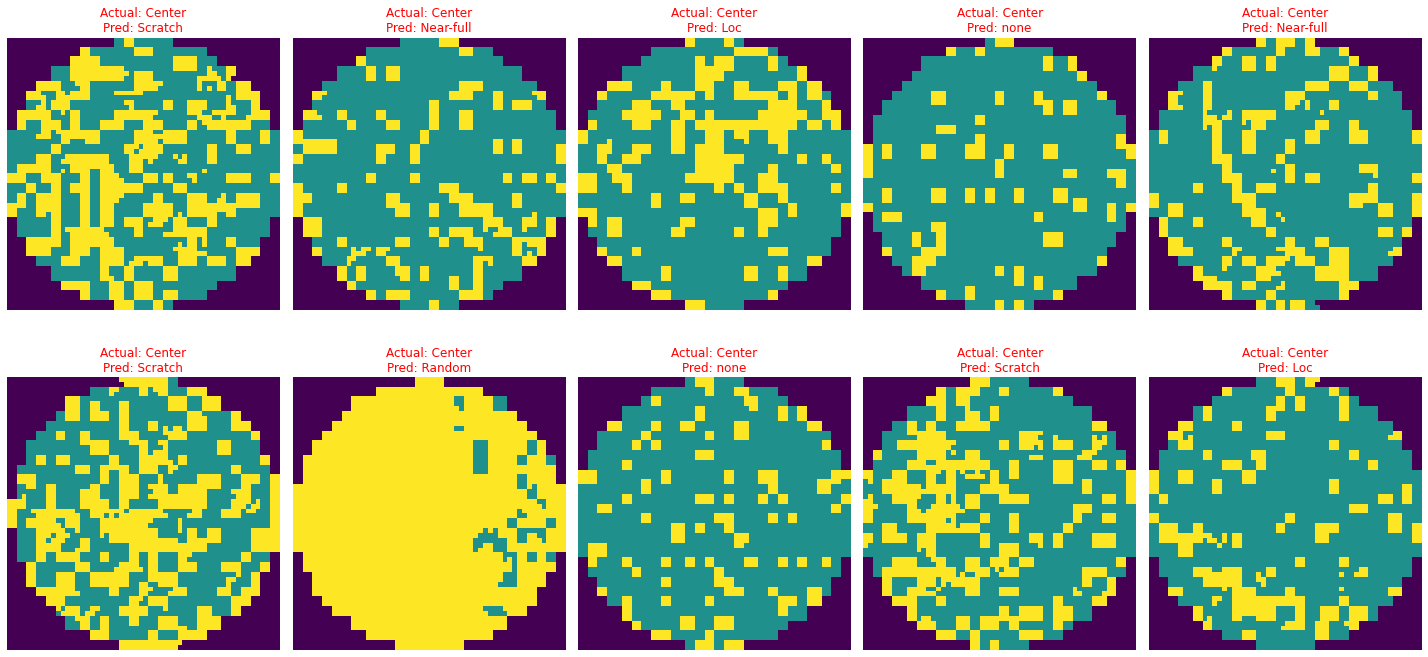

In [ ]:
def plot_misclassified(model, loader, device, mapping, num_images=10):
    model.eval()
    misclassified_images = []
    true_labels = []
    pred_labels = []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            out = model(inputs)

            # Convert to 1D numpy arrays
            preds = torch.argmax(out, dim=1).cpu().numpy().flatten()
            actuals = torch.argmax(labels, dim=1).cpu().numpy().flatten()

            for i in range(len(preds)):
                # Standard integer comparison
                p = int(preds[i])
                a = int(actuals[i])

                if p != a:
                    misclassified_images.append(inputs[i].cpu())
                    true_labels.append(a)
                    pred_labels.append(p)

                if len(misclassified_images) >= num_images:
                    break
            if len(misclassified_images) >= num_images:
                break

    num_found = len(misclassified_images)
    if num_found == 0:
        print("Amazing! No misclassifications found in this set.")
        return

    # Dynamic grid calculation
    cols = 5
    rows = (num_found // cols) + (1 if num_found % cols != 0 else 0)

    fig, axes = plt.subplots(rows, cols, figsize=(20, 5 * rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        if i < num_found:
            # Reconstruct the 2D wafer from the RGB channels for display
            img = misclassified_images[i].permute(1, 2, 0).numpy()
            ax.imshow(np.argmax(img, axis=2), cmap='viridis')
            ax.set_title(f"Actual: {mapping.get(true_labels[i])}\nPred: {mapping.get(pred_labels[i])}",
                         color='red', fontsize=12)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

plot_misclassified(CNN, test_loader, DEVICE, inv_mapping)

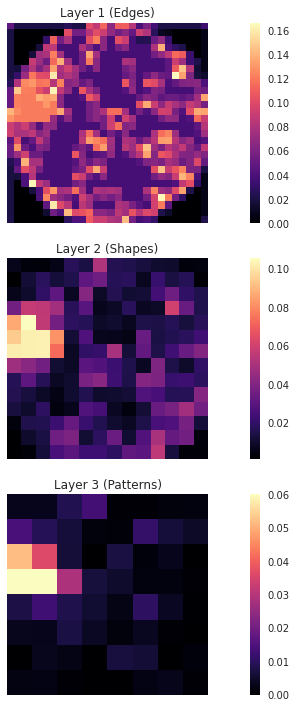

In [ ]:
def plot_all_layers_activation(model, wafer_tensor, device):
    model.eval()
    img = wafer_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        l1 = model.layer1(img)
        l2 = model.layer2(l1)
        l3 = model.layer3(l2)

    layers = [l1, l2, l3]
    layer_names = ['Layer 1 (Edges)', 'Layer 2 (Shapes)', 'Layer 3 (Patterns)']

    fig, axes = plt.subplots(3, 1, figsize=(15, 10))
    for i, (layer, name) in enumerate(zip(layers, layer_names)):
        # Mean across all filters in that layer to get a "heat" map
        act = torch.mean(layer, dim=1).squeeze().cpu().numpy()
        im = axes[i].imshow(act, cmap='magma')
        axes[i].set_title(name)
        axes[i].axis('off')
        plt.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

# Run for a wafer known to have a defect (e.g., index 0)
plot_all_layers_activation(CNN, resized_wm[0], DEVICE)

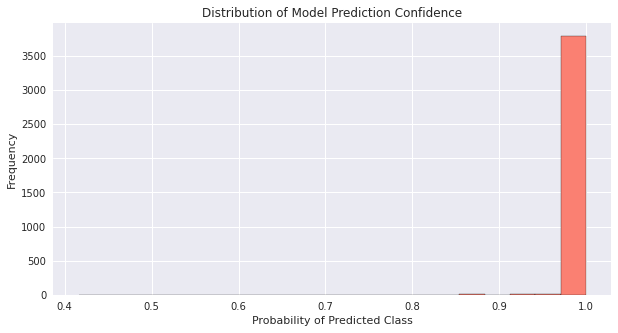

In [ ]:
def plot_confidence_distribution(model, loader, device):
    model.eval()
    confidences = []

    with torch.no_grad():
        for inputs, _ in loader:
            inputs = inputs.to(device)
            out = torch.softmax(model(inputs), dim=1)
            # Get the probability of the winning class
            max_probs, _ = torch.max(out, dim=1)
            confidences.extend(max_probs.cpu().numpy())

    plt.figure(figsize=(10, 5))
    plt.hist(confidences, bins=20, color='salmon', edgecolor='black')
    plt.title("Distribution of Model Prediction Confidence")
    plt.xlabel("Probability of Predicted Class")
    plt.ylabel("Frequency")
    plt.show()

plot_confidence_distribution(CNN, test_loader, DEVICE)

In [ ]:
from sklearn.metrics import classification_report
import torch
import torch.nn.functional as F

def get_classification_report(model, dataloader):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(DEVICE)

            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)

            y_pred.extend(preds.cpu().numpy())
            y_true.extend(torch.argmax(labels, dim=1).cpu().numpy())

    class_names = [
        "Center", "Donut", "Edge-Loc", "Edge-Ring",
        "Loc", "Near-full", "Random", "Scratch", "none"
    ]

    print("Classification Report:\n")
    print(classification_report(y_true, y_pred, target_names=class_names))


get_classification_report(model, test_loader)


Classification Report:
              precision    recall  f1-score   support

      Center       0.96      0.94      0.95       859
       Donut       0.84      0.88      0.86       111
    Edge-Loc       0.78      0.90      0.84      1038
   Edge-Ring       0.97      0.98      0.98      1936
         Loc       0.85      0.80      0.82       718
   Near-full       0.94      1.00      0.97        30
      Random       0.89      0.92      0.91       173
     Scratch       0.62      0.92      0.74       239
        none       0.99      0.99      0.99     29486

    accuracy                           0.98     34590
   macro avg       0.87      0.93      0.90     34590
weighted avg       0.98      0.98      0.98     34590



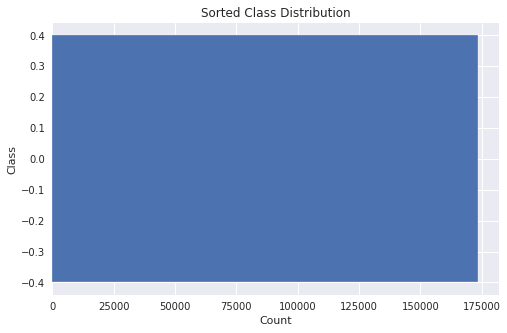

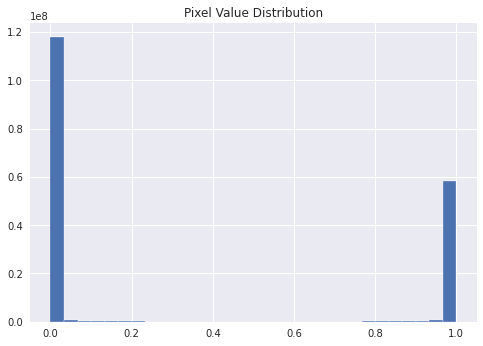

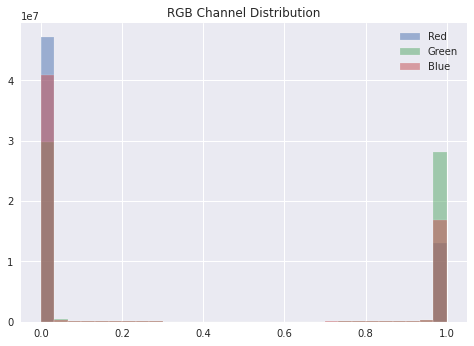

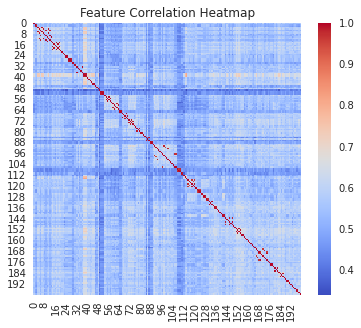

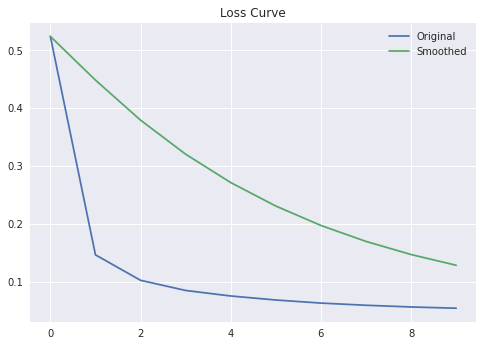

In [ ]:


import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize
from sklearn.decomposition import PCA

def get_labels(y):
    if isinstance(y, torch.Tensor):
        if len(y.shape) > 1:
            y = torch.argmax(y, dim=1)
        return y.cpu().numpy()
    else:
        return y

labels_np = get_labels(label_wm)
preds_np = np.array(all_preds) if 'all_preds' in globals() else None
true_np = np.array(all_labels) if 'all_labels' in globals() else None


# 1. SORTED CLASS DISTRIBUTION

unique, counts = np.unique(labels_np, return_counts=True)
sorted_idx = np.argsort(counts)

plt.figure(figsize=(8,5))
plt.barh(unique[sorted_idx], counts[sorted_idx])
plt.title("Sorted Class Distribution")
plt.xlabel("Count")
plt.ylabel("Class")
plt.show()


# 2. PIXEL VALUE DISTRIBUTION

data_np = resized_wm.cpu().numpy()

plt.figure()
plt.hist(data_np.flatten(), bins=30)
plt.title("Pixel Value Distribution")
plt.show()


# 3. RGB CHANNEL DISTRIBUTION

for i, name in enumerate(['Red','Green','Blue']):
    plt.hist(data_np[:,i,:,:].flatten(), bins=30, alpha=0.5, label=name)

plt.legend()
plt.title("RGB Channel Distribution")
plt.show()


# 4. CORRELATION HEATMAP (FIXED)

sample_data = resized_wm[:200].reshape(200, -1).cpu().numpy()
corr = np.corrcoef(sample_data)

plt.figure(figsize=(6,5))
sns.heatmap(corr, cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()


# 6. LOSS CURVE (SMOOTHED)

if 'losses' in globals():
    def smooth_curve(points, factor=0.8):
        smoothed=[]
        for p in points:
            if smoothed:
                smoothed.append(smoothed[-1]*factor + p*(1-factor))
            else:
                smoothed.append(p)
        return smoothed

    plt.plot(losses, label='Original')
    plt.plot(smooth_curve(losses), label='Smoothed')
    plt.legend()
    plt.title("Loss Curve")
    plt.show()

